In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output

sys.path.append('../')


import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [2]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [7]:

config = {
    
    "data": {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_small/labels.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_small/three_images/"
    },

    "hyperparams" :{
        "seed": 424,
        "batch_size": 64,
        "learning_rate": 0.0005,
        "randomize_labels": False,
        "backbone": "resnet18",
        "pretrained_backbone" : True,
        "in_channels": 4
    },



    "output": {
        "dir": "trained_models/"
    },

    "wandb": {
        "log_to_wandb" : "True",
        "project" : "project_2",
        "entity" : "janpisl",
        "group": ""
    }
}


In [8]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [9]:
x,y = next(iter(train_dl))

In [12]:
x.std()

tensor(0.1081)

In [15]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()

In [13]:
train_dataset = train_dl.dataset

In [27]:
train_dataset.img_labels

,geometry,driver,sampleid,split
0,POINT (-6.726781621781269 5.505369307436387),cocoa,3039418,train
1,POINT (-6.113681440369697 5.477072375986622),cocoa,3040124,train
2,POINT (-2.31246031561794 5.533666238886152),cocoa,3038914,train
3,POINT (-7.066344799178449 6.109037178364705),cocoa,3026449,train
4,POINT (-5.811847504905537 6.354277250929334),cocoa,3020208,train
...,...,...,...,...
8105,POINT (-44.16598121881418 -2.4855485596303044),urban,1297786,train
8106,POINT (-60.00633229569873 -3.032622567659093),urban,1027045,train
8107,POINT (-46.8447573960586 -23.343888813606505),urban,1600833,train
8108,POINT (-59.98571678698251 -3.0609194991088575),urban,1115047,train


soy


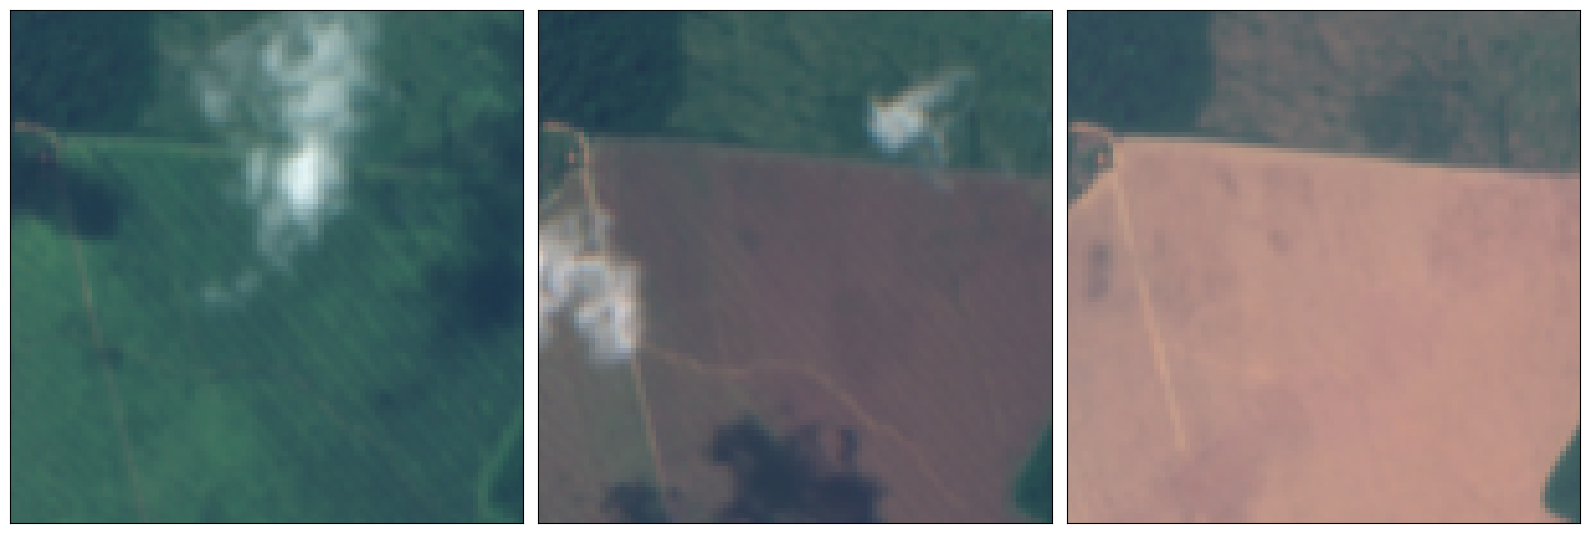

KeyboardInterrupt: Interrupted by user

In [23]:


for i in range(11, 5829, 112):


    ts, label = train_dataset.__getitem__(i)

    plot_images(ts, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [22]:
ts[2].mean()

tensor(0.1262)

## Visualize time series with TMF